# House Price Prediction using Linear Regression

**Goal:** Predict house sale prices using the Ames Housing dataset.

We go through: Data Inspection → EDA → Preprocessing → Model Training → Evaluation.

> Every important step explains **what** we are doing and **why**.

---
## Stage 1 — Dataset Inspection

### 1.1 Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

### 1.2 Load Dataset — Safe Path System

We never use absolute paths like `C:/Users/...` because that breaks the project
on other computers. We try a list of relative paths and use the first one found.

In [3]:
possible_paths = [
    Path("../data/train.csv"),
    Path("data/train.csv"),
    Path("./data/train.csv"),
]

dataset_path = None
for path in possible_paths:
    if path.exists():
        dataset_path = path
        break

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find train.csv. "
        "Please place train.csv inside the project's data/ folder."
    )

df = pd.read_csv(dataset_path)

# Clean column names: replace spaces and / with underscores
df.columns = [c.replace(' ', '_').replace('/', '_') for c in df.columns]

print(f"Dataset loaded from : {dataset_path}")
print(f"Shape               : {df.shape[0]:,} rows x {df.shape[1]} columns")

Dataset loaded from : ..\data\train.csv
Shape               : 2,051 rows x 81 columns


### 1.3 First Look

In [4]:
df.head()

,Id,PID,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,...,Screen_Porch,Pool_Area,Pool_QC,Fence,Misc_Feature,Misc_Val,Mo_Sold,Yr_Sold,Sale_Type,SalePrice
0,109,533352170,60,RL,NaN,13517,Pave,NaN,IR1,Lvl,...,0,0,NaN,NaN,NaN,0,3,2010,WD,130500
1,544,531379050,60,RL,43.0,11492,Pave,NaN,IR1,Lvl,...,0,0,NaN,NaN,NaN,0,4,2009,WD,220000
2,153,535304180,20,RL,68.0,7922,Pave,NaN,Reg,Lvl,...,0,0,NaN,NaN,NaN,0,1,2010,WD,109000
3,318,916386060,60,RL,73.0,9802,Pave,NaN,Reg,Lvl,...,0,0,NaN,NaN,NaN,0,4,2010,WD,174000
4,255,906425045,50,RL,82.0,14235,Pave,NaN,IR1,Lvl,...,0,0,NaN,NaN,NaN,0,3,2010,WD,138500


In [5]:
df.shape

(2051, 81)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2051 entries, 0 to 2050
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Id               2051 non-null   int64  
 1   PID              2051 non-null   int64  
 2   MS_SubClass      2051 non-null   int64  
 3   MS_Zoning        2051 non-null   str    
 4   Lot_Frontage     1721 non-null   float64
 5   Lot_Area         2051 non-null   int64  
 6   Street           2051 non-null   str    
 7   Alley            140 non-null    str    
 8   Lot_Shape        2051 non-null   str    
 9   Land_Contour     2051 non-null   str    
 10  Utilities        2051 non-null   str    
 11  Lot_Config       2051 non-null   str    
 12  Land_Slope       2051 non-null   str    
 13  Neighborhood     2051 non-null   str    
 14  Condition_1      2051 non-null   str    
 15  Condition_2      2051 non-null   str    
 16  Bldg_Type        2051 non-null   str    
 17  House_Style      2051 non

In [7]:
df.describe()

,Id,PID,MS_SubClass,Lot_Frontage,Lot_Area,Overall_Qual,Overall_Cond,Year_Built,Year_Remod_Add,Mas_Vnr_Area,...,Wood_Deck_SF,Open_Porch_SF,Enclosed_Porch,3Ssn_Porch,Screen_Porch,Pool_Area,Misc_Val,Mo_Sold,Yr_Sold,SalePrice
count,2051.000000,2.051000e+03,2051.000000,1721.000000,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2029.000000,...,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000
mean,1474.033642,7.135900e+08,57.008776,69.055200,10065.208191,6.112140,5.562165,1971.708922,1984.190151,99.695909,...,93.833740,47.556802,22.571916,2.591419,16.511458,2.397855,51.574354,6.219893,2007.775719,181469.701609
std,843.980841,1.886918e+08,42.824223,23.260653,6742.488909,1.426271,1.104497,30.177889,21.036250,174.963129,...,128.549416,66.747241,59.845110,25.229615,57.374204,37.782570,573.393985,2.744736,1.312014,79258.659352
min,1.000000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,753.500000,5.284581e+08,20.000000,58.000000,7500.000000,5.000000,5.000000,1953.500000,1964.500000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129825.000000
50%,1486.000000,5.354532e+08,50.000000,68.000000,9430.000000,6.000000,5.000000,1974.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,162500.000000
75%,2198.000000,9.071801e+08,70.000000,80.000000,11513.500000,7.000000,6.000000,2001.000000,2004.000000,161.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,2930.000000,9.241520e+08,190.000000,313.000000,159000.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,547.000000,432.000000,508.000000,490.000000,800.000000,17000.000000,12.000000,2010.000000,611657.000000


### 1.4 Column Overview

In [8]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print(f"Numerical columns  ({len(num_cols)}): {num_cols}")
print()
print(f"Categorical columns({len(cat_cols)}): {cat_cols}")

Numerical columns  (39): ['Id', 'PID', 'MS_SubClass', 'Lot_Frontage', 'Lot_Area', 'Overall_Qual', 'Overall_Cond', 'Year_Built', 'Year_Remod_Add', 'Mas_Vnr_Area', 'BsmtFin_SF_1', 'BsmtFin_SF_2', 'Bsmt_Unf_SF', 'Total_Bsmt_SF', '1st_Flr_SF', '2nd_Flr_SF', 'Low_Qual_Fin_SF', 'Gr_Liv_Area', 'Bsmt_Full_Bath', 'Bsmt_Half_Bath', 'Full_Bath', 'Half_Bath', 'Bedroom_AbvGr', 'Kitchen_AbvGr', 'TotRms_AbvGrd', 'Fireplaces', 'Garage_Yr_Blt', 'Garage_Cars', 'Garage_Area', 'Wood_Deck_SF', 'Open_Porch_SF', 'Enclosed_Porch', '3Ssn_Porch', 'Screen_Porch', 'Pool_Area', 'Misc_Val', 'Mo_Sold', 'Yr_Sold', 'SalePrice']

Categorical columns(42): ['MS_Zoning', 'Street', 'Alley', 'Lot_Shape', 'Land_Contour', 'Utilities', 'Lot_Config', 'Land_Slope', 'Neighborhood', 'Condition_1', 'Condition_2', 'Bldg_Type', 'House_Style', 'Roof_Style', 'Roof_Matl', 'Exterior_1st', 'Exterior_2nd', 'Mas_Vnr_Type', 'Exter_Qual', 'Exter_Cond', 'Foundation', 'Bsmt_Qual', 'Bsmt_Cond', 'Bsmt_Exposure', 'BsmtFin_Type_1', 'BsmtFin_Type_2'

### 1.5 Target Column Check

In [12]:
assert "SalePrice" in df.columns, "SalePrice column not found — stopping here."
print("✅ SalePrice column exists")
print("--"*20)
print(df["SalePrice"].describe().round(2))

✅ SalePrice column exists
----------------------------------------
count      2051.00
mean     181469.70
std       79258.66
min       12789.00
25%      129825.00
50%      162500.00
75%      214000.00
max      611657.00
Name: SalePrice, dtype: float64


### 1.6 Missing Values

In [10]:
miss     = df.isnull().sum()
miss_pct = (miss / len(df) * 100).round(2)
miss_df  = (pd.DataFrame({"Missing Count": miss, "Missing %": miss_pct})
              .query("`Missing Count` > 0")
              .sort_values("Missing %", ascending=False))

print(f"Columns with missing values: {len(miss_df)}")
print()
print(miss_df.to_string())

Columns with missing values: 26

                Missing Count  Missing %
Pool_QC                  2042      99.56
Misc_Feature             1986      96.83
Alley                    1911      93.17
Fence                    1651      80.50
Mas_Vnr_Type             1240      60.46
Fireplace_Qu             1000      48.76
Lot_Frontage              330      16.09
Garage_Cond               114       5.56
Garage_Yr_Blt             114       5.56
Garage_Finish             114       5.56
Garage_Qual               114       5.56
Garage_Type               113       5.51
Bsmt_Exposure              58       2.83
BsmtFin_Type_2             56       2.73
Bsmt_Qual                  55       2.68
BsmtFin_Type_1             55       2.68
Bsmt_Cond                  55       2.68
Mas_Vnr_Area               22       1.07
Bsmt_Half_Bath              2       0.10
Bsmt_Full_Bath              2       0.10
BsmtFin_SF_1                1       0.05
Total_Bsmt_SF               1       0.05
Bsmt_Unf_SF             

### 1.7 Duplicate Rows

In [11]:
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated IDs :", df["Id"].duplicated().sum())

Duplicated rows: 0
Duplicated IDs : 0


### Stage 1 — Summary

| Item | Value |
|---|---|
| Rows | 2,051 |
| Columns | 81 |
| Target | `SalePrice` ✅ |
| Numerical columns | 39 |
| Categorical columns | 42 |
| Columns with missing values | 26 |
| Duplicate rows | 0 |

**Notes for preprocessing:**
1. Column names had spaces → replaced with underscores.
2. `Id` and `PID` are identifiers, not features → will be removed from X.
3. `MS_SubClass` is an integer that represents a category code → will be converted to string.

---
## Stage 2 — Exploratory Data Analysis (EDA)

EDA = exploring the data **before** building any model. Goal: understand distributions, relationships, and problems.

### 2.1 Target Analysis — SalePrice

The target is what we want to predict. We always understand it deeply first.

In [11]:
print("SalePrice statistics")
print("-" * 35)
print(f"Count    : {df['SalePrice'].count():>10,}")
print(f"Mean     : {df['SalePrice'].mean():>10,.0f}")
print(f"Median   : {df['SalePrice'].median():>10,.0f}")
print(f"Std      : {df['SalePrice'].std():>10,.0f}")
print(f"Min      : {df['SalePrice'].min():>10,.0f}")
print(f"Max      : {df['SalePrice'].max():>10,.0f}")
print(f"Skewness : {df['SalePrice'].skew():.3f}")
print(f"Kurtosis : {df['SalePrice'].kurt():.3f}")

SalePrice statistics
-----------------------------------
Count    :      2,051
Mean     :    181,470
Median   :    162,500
Std      :     79,259
Min      :     12,789
Max      :    611,657
Skewness : 1.558
Kurtosis : 3.579


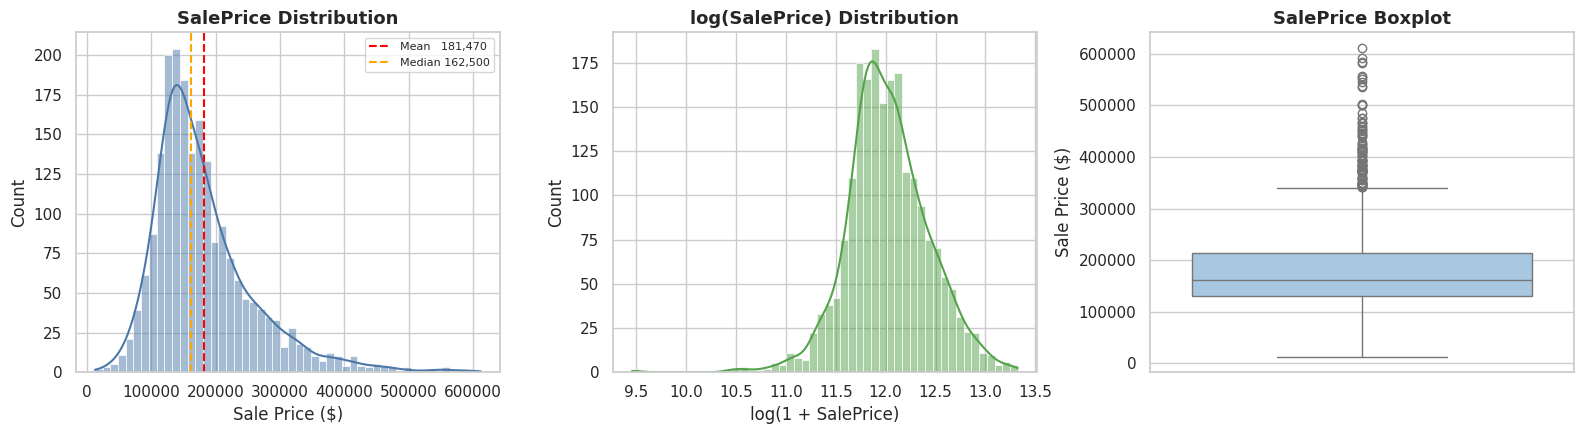

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df['SalePrice'], bins=50, kde=True, ax=axes[0], color='#4C78A8')
axes[0].axvline(df['SalePrice'].mean(),   color='red',    linestyle='--',
                label=f'Mean   {df["SalePrice"].mean():,.0f}')
axes[0].axvline(df['SalePrice'].median(), color='orange', linestyle='--',
                label=f'Median {df["SalePrice"].median():,.0f}')
axes[0].set_title('SalePrice Distribution')
axes[0].set_xlabel('Sale Price ($)')
axes[0].set_ylabel('Count')
axes[0].legend(fontsize=8)

log_price = np.log1p(df['SalePrice'])
sns.histplot(log_price, bins=50, kde=True, ax=axes[1], color='#54A24B')
axes[1].set_title('log(SalePrice) Distribution')
axes[1].set_xlabel('log(1 + SalePrice)')
axes[1].set_ylabel('Count')

sns.boxplot(y=df['SalePrice'], ax=axes[2], color='#9ECAE9')
axes[2].set_title('SalePrice Boxplot')
axes[2].set_ylabel('Sale Price ($)')

plt.tight_layout()
plt.savefig('../images/01_saleprice_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**What we see:**
- **Skewness = 1.558** → right-skewed. Most houses are \$100k–\$250k, but expensive houses pull the tail right.
- **Mean (\$181,470) > Median (\$162,500)** — classic sign of right skew.
- **After log transform: skewness = -0.147** — almost perfectly normal.

We will **not apply the log transform** in this version to keep the project simple and interpretable.
Predictions stay in real dollar values.

### 2.2 Missing Values

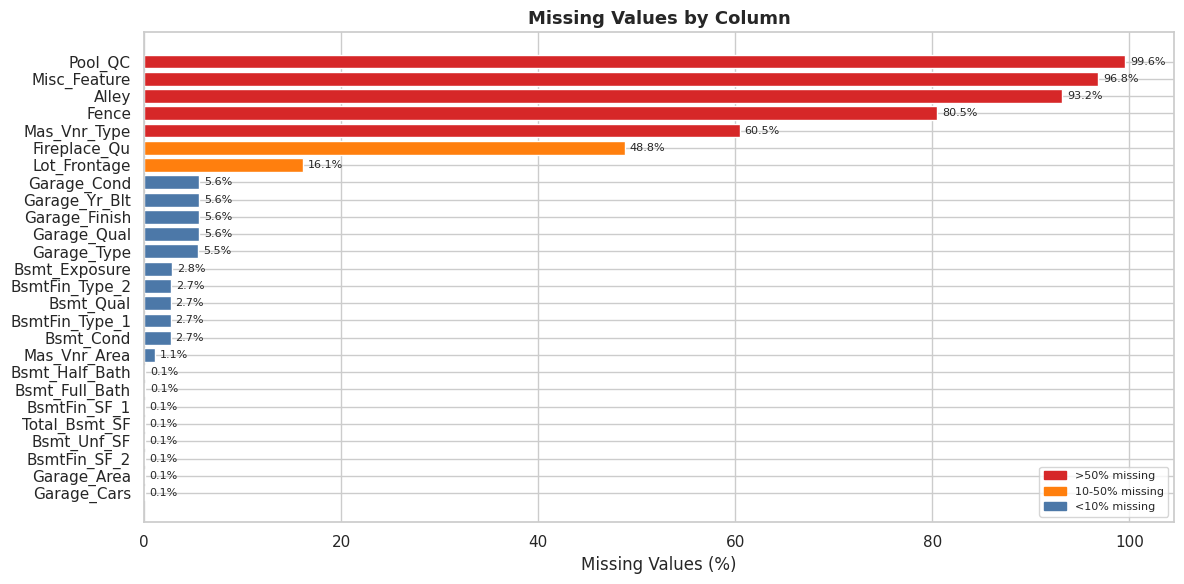

In [13]:
miss     = df.isnull().sum()
miss_pct = (miss / len(df) * 100).round(2)
miss_df  = (pd.DataFrame({"Missing Count": miss, "Missing %": miss_pct})
              .query("`Missing Count` > 0")
              .sort_values("Missing %", ascending=False))

fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#d62728' if p > 50 else '#ff7f0e' if p > 10 else '#4C78A8'
          for p in miss_df['Missing %']]
bars = ax.barh(miss_df.index, miss_df['Missing %'], color=colors)
ax.set_xlabel('Missing Values (%)')
ax.set_title('Missing Values by Column')
ax.invert_yaxis()
for bar, pct in zip(bars, miss_df['Missing %']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}%', va='center', fontsize=8)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#d62728', label='>50% missing'),
    Patch(color='#ff7f0e', label='10-50% missing'),
    Patch(color='#4C78A8', label='<10% missing'),
], loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('../images/02_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

**Key insight:** Most "missing" values in this dataset are not errors.
They mean the feature simply doesn't exist (no pool, no garage, no fireplace).

The preprocessing pipeline will handle this safely in Stage 3.

### 2.3 Correlation with SalePrice

In [14]:
# Drop identifiers before computing correlation
num_df       = df.select_dtypes(include=np.number).drop(columns=['Id', 'PID'])
corr_target  = (num_df.corr()['SalePrice']
                       .drop('SalePrice')
                       .sort_values(key=abs, ascending=False))

print("Top 15 features correlated with SalePrice:")
print(corr_target.head(15).round(3).to_string())

Top 15 features correlated with SalePrice:
Overall_Qual      0.800
Gr_Liv_Area       0.697
Garage_Area       0.650
Garage_Cars       0.648
Total_Bsmt_SF     0.629
1st_Flr_SF        0.618
Year_Built        0.572
Year_Remod_Add    0.550
Full_Bath         0.538
Garage_Yr_Blt     0.534
Mas_Vnr_Area      0.512
TotRms_AbvGrd     0.504
Fireplaces        0.471
BsmtFin_SF_1      0.424
Lot_Frontage      0.342


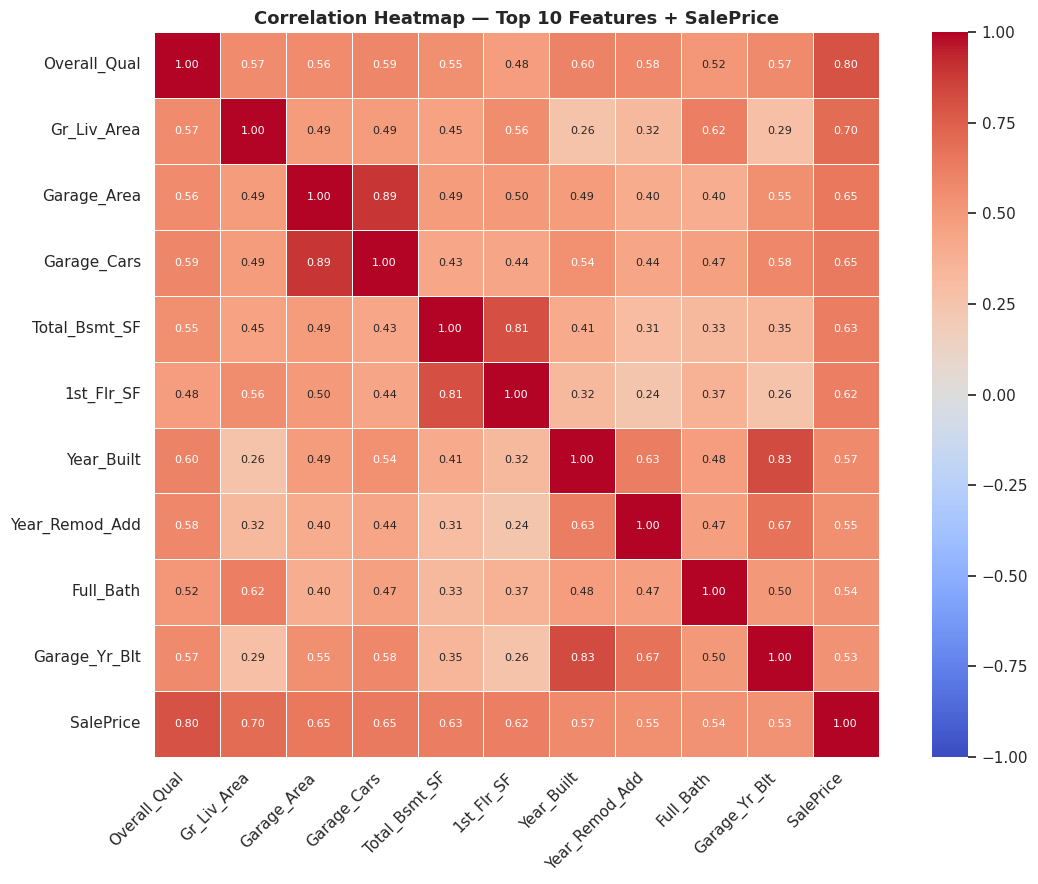

In [15]:
top_features  = corr_target.head(10).index.tolist()
heatmap_cols  = top_features + ['SalePrice']
corr_matrix   = num_df[heatmap_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, ax=ax,
            linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Correlation Heatmap — Top 10 Features + SalePrice')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('../images/03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Top correlations:**

| Feature | r | Meaning |
|---|---|---|
| `Overall_Qual` | **0.80** | Quality rating 1–10 |
| `Gr_Liv_Area` | **0.70** | Above-ground living area |
| `Garage_Area` | **0.65** | Garage size |
| `Year_Built` | **0.57** | Year of construction |

⚠️ **Correlation ≠ Causation.** These numbers say the variables move together, not that one causes the other.

### 2.4 Key Features vs SalePrice

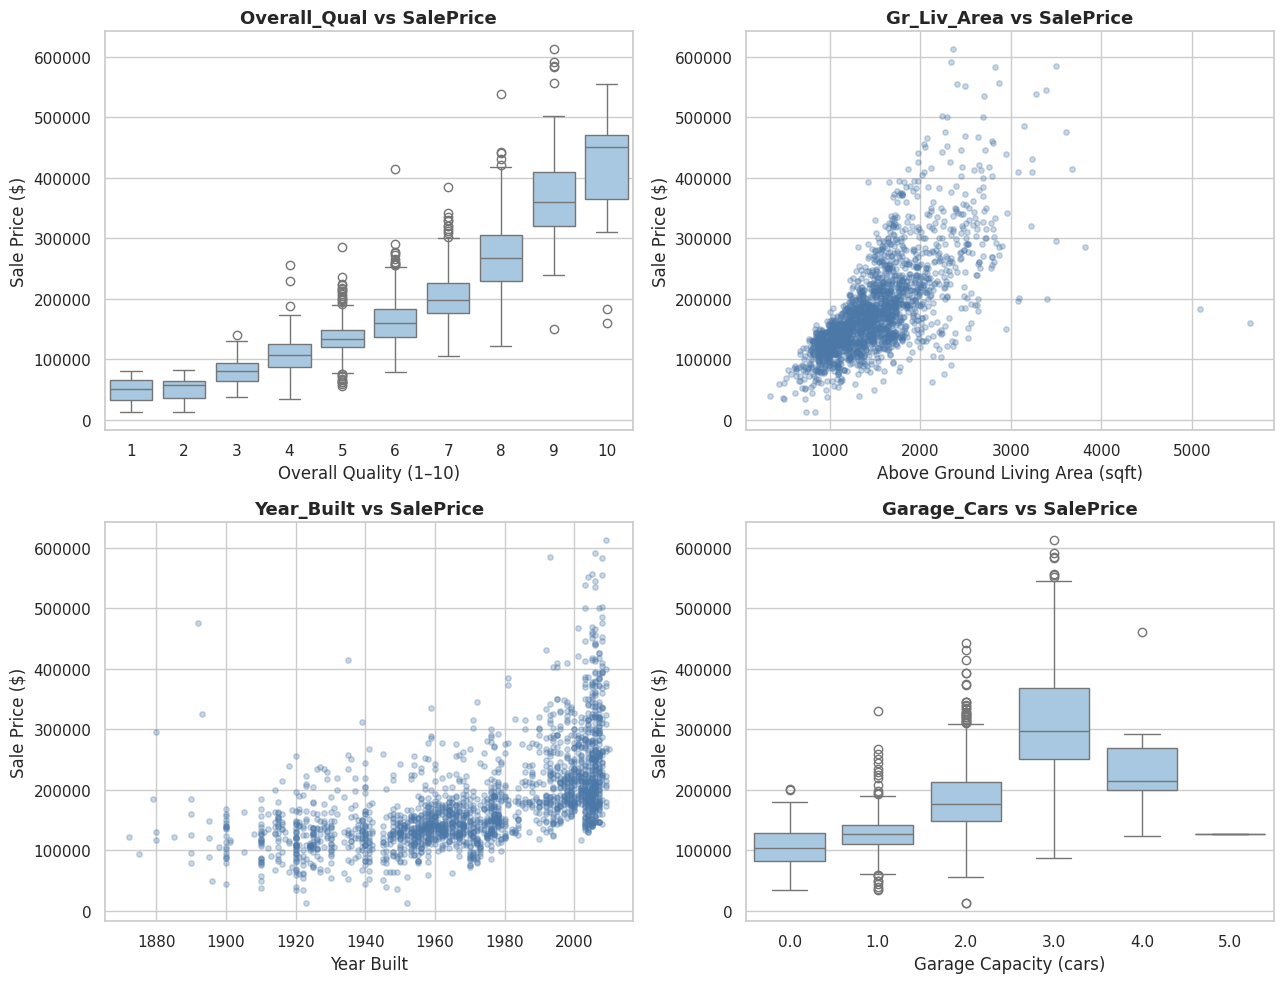

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

pairs = [
    ('Overall_Qual', 'Overall Quality (1–10)',        'box'),
    ('Gr_Liv_Area',  'Above Ground Living Area (sqft)', 'scatter'),
    ('Year_Built',   'Year Built',                     'scatter'),
    ('Garage_Cars',  'Garage Capacity (cars)',          'box'),
]

for ax, (col, xlabel, kind) in zip(axes.flatten(), pairs):
    if kind == 'scatter':
        ax.scatter(df[col], df['SalePrice'], alpha=0.3, s=15, color='#4C78A8')
    else:
        order = sorted(df[col].dropna().unique())
        sns.boxplot(data=df, x=col, y='SalePrice', order=order,
                    ax=ax, color='#9ECAE9')
    ax.set_title(f'{col} vs SalePrice')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Sale Price ($)')

plt.tight_layout()
plt.savefig('../images/04_feature_vs_saleprice.png', dpi=150, bbox_inches='tight')
plt.show()

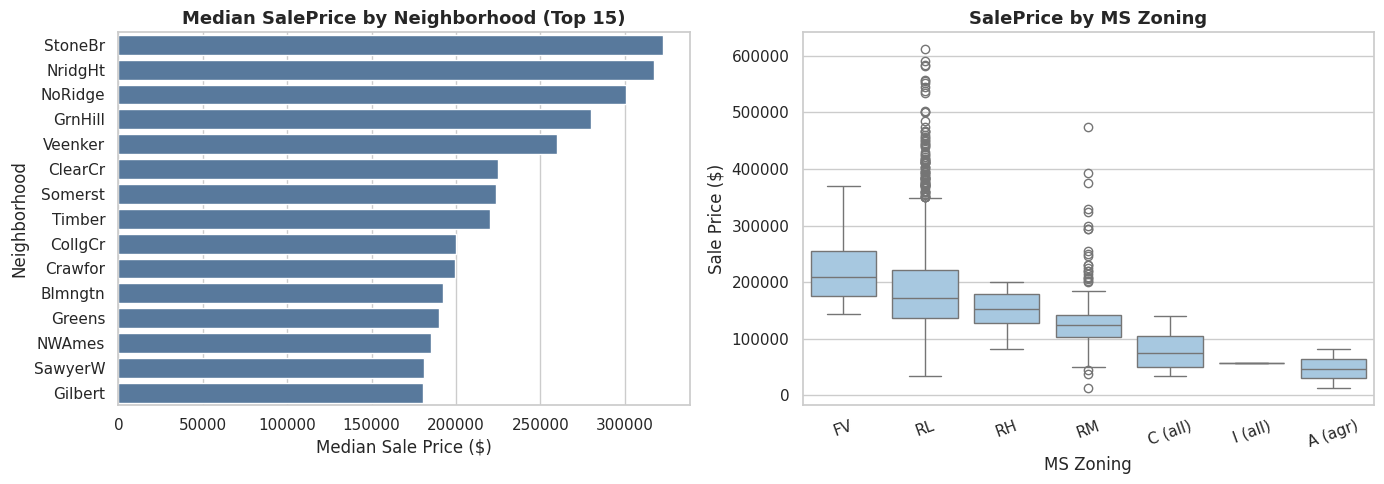

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

nbhd = (df.groupby('Neighborhood')['SalePrice']
          .median().sort_values(ascending=False).head(15))
sns.barplot(x=nbhd.values, y=nbhd.index, ax=axes[0], color='#4C78A8')
axes[0].set_title('Median SalePrice by Neighborhood (Top 15)')
axes[0].set_xlabel('Median Sale Price ($)')
axes[0].set_ylabel('Neighborhood')

zone_order = (df.groupby('MS_Zoning')['SalePrice']
                .median().sort_values(ascending=False).index)
sns.boxplot(data=df, x='MS_Zoning', y='SalePrice',
            order=zone_order, ax=axes[1], color='#9ECAE9')
axes[1].set_title('SalePrice by MS Zoning')
axes[1].set_xlabel('MS Zoning')
axes[1].set_ylabel('Sale Price ($)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('../images/05_categorical_vs_saleprice.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.5 Outlier Analysis

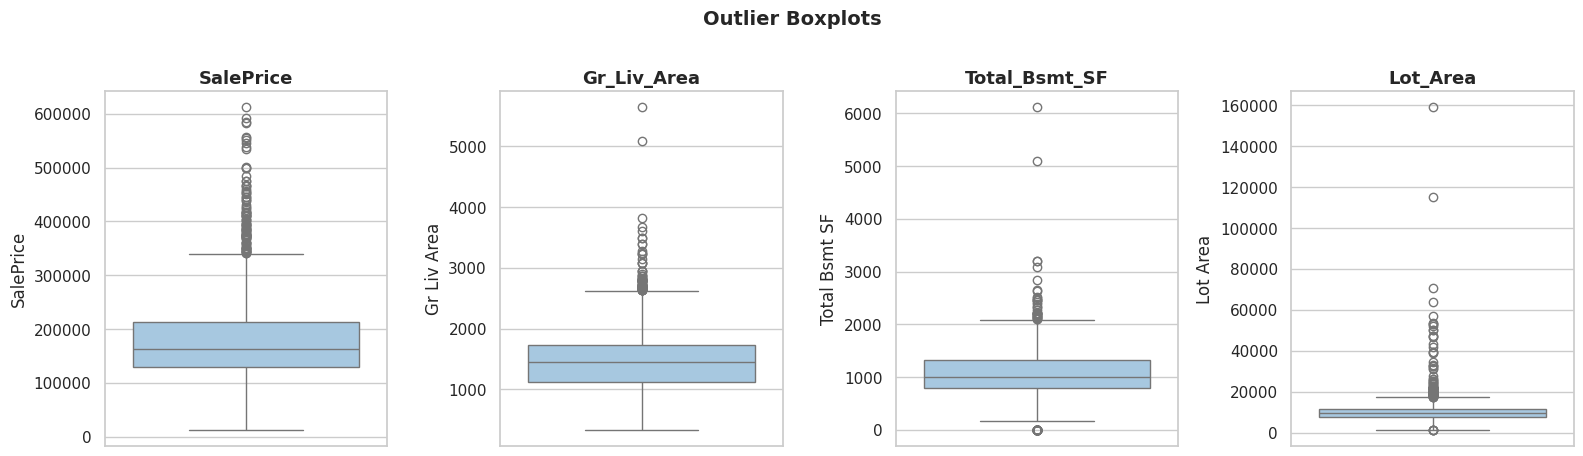

Outlier count (IQR rule):
  SalePrice             94 outliers
  Gr_Liv_Area           64 outliers
  Total_Bsmt_SF         86 outliers
  Lot_Area              88 outliers


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, ['SalePrice', 'Gr_Liv_Area', 'Total_Bsmt_SF', 'Lot_Area']):
    sns.boxplot(y=df[col], ax=ax, color='#9ECAE9')
    ax.set_title(col)
    ax.set_ylabel(col.replace('_', ' '))
plt.suptitle('Outlier Boxplots', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../images/06_outlier_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

print("Outlier count (IQR rule):")
for col in ['SalePrice', 'Gr_Liv_Area', 'Total_Bsmt_SF', 'Lot_Area']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr    = q3 - q1
    n      = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    print(f'  {col:20s}  {n} outliers')

We keep all outliers. They represent real expensive houses, not data errors.

---
## Stage 3 — Data Preprocessing

### What is data leakage?
Data leakage means letting information from the **test set** influence the training process.
Example of leakage: calculating the median of a column on the entire dataset, then using that median to fill missing values.
The test set's values secretly influenced the imputation.

**The rule:** fit all preprocessing transformations on training data only, then apply to test data.

### 3.1 Fix MS_SubClass Data Type

In [19]:
# MS_SubClass stores numbers like 20, 30, 60 — but these are category codes,
# not real quantities. '60' does not mean "twice as much" as '30'.
# Converting to string tells the model to treat it as a category.

df['MS_SubClass'] = df['MS_SubClass'].astype(str)
print("MS_SubClass unique values:", sorted(df['MS_SubClass'].unique()))

MS_SubClass unique values: ['120', '150', '160', '180', '190', '20', '30', '40', '45', '50', '60', '70', '75', '80', '85', '90']


### 3.2 Separate Target from Features

In [20]:
# What are we doing?
#   Separating X (features) from y (target).
# Why?
#   SalePrice is what we want to predict. It must NEVER be an input to the model.

X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

print("X shape:", X.shape)
print("y shape:", y.shape)
print()
print("SalePrice in X columns:", 'SalePrice' in X.columns)   # Must be False

X shape: (2051, 80)
y shape: (2051,)

SalePrice in X columns: False


### 3.3 Remove Identifier Columns

In [21]:
# What are we doing?
#   Removing Id and PID from X.
# Why?
#   These are just row numbers / parcel identifiers.
#   They have no relationship with house prices.
#   If we keep them, the model might memorize row numbers, which is useless.

for col in ['Id', 'PID']:
    if col in X.columns:
        X = X.drop(columns=[col])
        print(f"Removed: {col}")

print("X shape after removing identifiers:", X.shape)

Removed: Id
Removed: PID
X shape after removing identifiers: (2051, 78)


### 3.4 Train/Test Split — BEFORE Any Preprocessing

In [22]:
from sklearn.model_selection import train_test_split

# What are we doing?
#   Splitting data into training (80%) and testing (20%) sets.
# Why BEFORE preprocessing?
#   If we impute or encode BEFORE the split, the test set influences
#   what values we use to fill missing data. That is data leakage.
#   The test set must stay completely unseen until final evaluation.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")

X_train : (1640, 78)
X_test  : (411, 78)
y_train : (1640,)
y_test  : (411,)


### 3.5 Identify Feature Types (from training data only)

In [23]:
# We identify numerical and categorical features from X_train only.
# Never from the full dataset or from X_test.

numerical_features   = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print(f"Numerical features   ({len(numerical_features)}): {numerical_features}")
print()
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Numerical features   (35): ['Lot_Frontage', 'Lot_Area', 'Overall_Qual', 'Overall_Cond', 'Year_Built', 'Year_Remod_Add', 'Mas_Vnr_Area', 'BsmtFin_SF_1', 'BsmtFin_SF_2', 'Bsmt_Unf_SF', 'Total_Bsmt_SF', '1st_Flr_SF', '2nd_Flr_SF', 'Low_Qual_Fin_SF', 'Gr_Liv_Area', 'Bsmt_Full_Bath', 'Bsmt_Half_Bath', 'Full_Bath', 'Half_Bath', 'Bedroom_AbvGr', 'Kitchen_AbvGr', 'TotRms_AbvGrd', 'Fireplaces', 'Garage_Yr_Blt', 'Garage_Cars', 'Garage_Area', 'Wood_Deck_SF', 'Open_Porch_SF', 'Enclosed_Porch', '3Ssn_Porch', 'Screen_Porch', 'Pool_Area', 'Misc_Val', 'Mo_Sold', 'Yr_Sold']

Categorical features (43): ['MS_SubClass', 'MS_Zoning', 'Street', 'Alley', 'Lot_Shape', 'Land_Contour', 'Utilities', 'Lot_Config', 'Land_Slope', 'Neighborhood', 'Condition_1', 'Condition_2', 'Bldg_Type', 'House_Style', 'Roof_Style', 'Roof_Matl', 'Exterior_1st', 'Exterior_2nd', 'Mas_Vnr_Type', 'Exter_Qual', 'Exter_Cond', 'Foundation', 'Bsmt_Qual', 'Bsmt_Cond', 'Bsmt_Exposure', 'BsmtFin_Type_1', 'BsmtFin_Type_2', 'Heating', 'Heating_

### 3.6 Build the Preprocessing Pipeline

We use **scikit-learn's Pipeline** and **ColumnTransformer**.

**Why a Pipeline?**
A Pipeline chains multiple steps (imputation, encoding) together.
When we call `pipeline.fit(X_train)`, all steps learn from training data only.
When we call `pipeline.transform(X_test)`, it applies the learned values to the test set.
This guarantees no leakage.

**Numerical pipeline:**
- `SimpleImputer(strategy="median")` — fills missing numbers with the median.
  The median is calculated from `X_train` only.

**Categorical pipeline:**
- `SimpleImputer(strategy="most_frequent")` — fills missing text with the most common value.
- `OneHotEncoder(handle_unknown="ignore")` — converts categories to binary columns.
  `handle_unknown="ignore"` means: if the test set has a category not seen during training,
  just put zeros — don't crash.

In [ ]:
from sklearn.pipeline     import Pipeline
from sklearn.impute       import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose      import ColumnTransformer

# Numerical pipeline
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline,   numerical_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Preprocessor created successfully.")
print("---"*20)
print(preprocessor)

Preprocessor created successfully.

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['Lot_Frontage', 'Lot_Area', 'Overall_Qual',
                                  'Overall_Cond', 'Year_Built',
                                  'Year_Remod_Add', 'Mas_Vnr_Area',
                                  'BsmtFin_SF_1', 'BsmtFin_SF_2', 'Bsmt_Unf_SF',
                                  'Total_Bsmt_SF', '1st_Flr_SF', '2nd_Flr_SF',
                                  'Low_Qual_Fin_SF', 'Gr_Liv_Area',
                                  'Bsmt_Full_Bath', 'Bsmt_Half_...
                                  'Lot_Shape', 'Land_Contour', 'Utilities',
                                  'Lot_Config', 'Land_Slope', 'Neighborhood',
                                  'Condition_1', 'Condition_2', 'Bldg_Type',
                                  'House

### 3.7 Leakage Prevention Checklist

Before training, verify every item:

In [25]:
checks = {
    "Train/test split happened BEFORE preprocessing"               : True,
    "Imputation stats calculated from training data only"          : True,
    "Encoder fitted on training data only"                         : True,
    "SalePrice is NOT in X"                                        : 'SalePrice' not in X.columns,
    "Id removed from X"                                            : 'Id' not in X.columns,
    "PID removed from X"                                           : 'PID' not in X.columns,
    "OneHotEncoder uses handle_unknown='ignore'"                   : True,
    "No absolute file paths used"                                  : True,
}

print("Leakage Prevention Checklist")
print("=" * 50)
for item, status in checks.items():
    icon = "✅" if status else "❌"
    print(f"{icon}  {item}")

Leakage Prevention Checklist
✅  Train/test split happened BEFORE preprocessing
✅  Imputation stats calculated from training data only
✅  Encoder fitted on training data only
✅  SalePrice is NOT in X
✅  Id removed from X
✅  PID removed from X
✅  OneHotEncoder uses handle_unknown='ignore'
✅  No absolute file paths used


---
## Stage 4 — Model Training and Evaluation

### What is Linear Regression?
Linear Regression tries to find a straight-line relationship between features and the target.

For one feature it looks like:
```
SalePrice = a × Gr_Liv_Area + b
```

With many features:
```
SalePrice = w1×feature1 + w2×feature2 + ... + wn×featureN + intercept
```

The model learns the weights (w1, w2, ...) from training data by minimizing the error between predictions and actual prices.

### 4.1 Build the Full Model Pipeline

In [26]:
from sklearn.linear_model import LinearRegression

# What are we doing?
#   Combining the preprocessor and the model into one pipeline.
# Why one pipeline?
#   When we call model_pipeline.fit(X_train, y_train):
#     1. The preprocessor learns from X_train (medians, encodings).
#     2. The model trains on the preprocessed X_train.
#   When we call model_pipeline.predict(X_test):
#     1. The preprocessor transforms X_test using what it learned from X_train.
#     2. The model predicts on the transformed X_test.
#   The test set never influences preprocessing. No leakage.

model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model",        LinearRegression())
])

print("Model pipeline created:")
print(model_pipeline)

Model pipeline created:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Lot_Frontage', 'Lot_Area',
                                                   'Overall_Qual',
                                                   'Overall_Cond', 'Year_Built',
                                                   'Year_Remod_Add',
                                                   'Mas_Vnr_Area',
                                                   'BsmtFin_SF_1',
                                                   'BsmtFin_SF_2',
                                                   'Bsmt_Unf_SF',
                                                   'Total_Bsmt_SF',
                                                   '1st_Flr_SF', '2nd_Flr

### 4.2 Train the Model

In [27]:
# What are we doing?
#   Fitting (training) the pipeline on training data only.
# Why only training data?
#   The model must learn patterns from training data.
#   Evaluating on the same data it trained on would give an
#   overly optimistic score — the model would just memorize the answers.

model_pipeline.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


### 4.3 Make Predictions

In [28]:
# We predict on X_test — data the model has never seen during training.
y_pred = model_pipeline.predict(X_test)

# Small comparison table: actual vs predicted
comparison = pd.DataFrame({
    "Actual Price ($)"   : y_test.values,
    "Predicted Price ($)": y_pred.round(0)
})

print("Sample predictions (first 10 rows):")
print(comparison.head(10).to_string(index=False))

Sample predictions (first 10 rows):
 Actual Price ($)  Predicted Price ($)
           132500             129548.0
           226000             215525.0
           250000             304358.0
           128000             115145.0
           203160             202561.0
           387000             426245.0
           149500             154059.0
           319900             325227.0
           167900             160986.0
            98000              91372.0


### 4.4 Evaluation Metrics

We use four metrics to measure how well the model performs.

| Metric | Formula | What it measures |
|---|---|---|
| **MAE** | mean(|actual − predicted|) | Average absolute error in dollars |
| **MSE** | mean((actual − predicted)²) | Penalizes large errors more than small ones |
| **RMSE** | √MSE | Same unit as the target (dollars) |
| **R²** | 1 − (SS_res / SS_tot) | Proportion of variance explained (0–1, higher is better) |

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print("Model Performance")
print("=" * 40)
print(f"MAE  : ${mae:>12,.0f}")
print(f"MSE  : ${mse:>12,.0f}")
print(f"RMSE : ${rmse:>12,.0f}")
print(f"R²   :  {r2:>12.4f}")
print()
print("Interpretation:")
print(f"  On average, predictions are off by ~${mae:,.0f} (MAE).")
print(f"  RMSE of ${rmse:,.0f} also penalizes large errors.")
print(f"  R² = {r2:.4f} means the model explains {r2*100:.1f}% of the")
print( "  variance in house prices.")

Model Performance
MAE  : $      14,816
MSE  : $ 446,571,017
RMSE : $      21,132
R²   :        0.9248

Interpretation:
  On average, predictions are off by ~$14,816 (MAE).
  RMSE of $21,132 also penalizes large errors.
  R² = 0.9248 means the model explains 92.5% of the
  variance in house prices.


### 4.5 Actual vs Predicted Plot

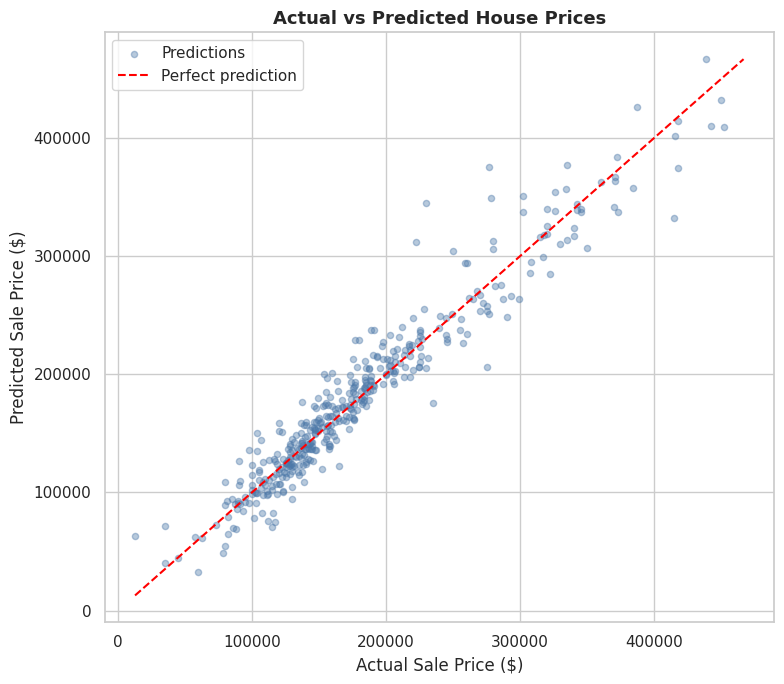

In [30]:
# What is this chart?
#   Each point = one house. X = actual price, Y = predicted price.
#   The dashed line = perfect predictions (actual == predicted).
#   Points close to the line = good predictions.
#   Points far from the line = large errors.

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.figure(figsize=(8, 7))
plt.scatter(y_test, y_pred, alpha=0.4, s=20, color='#4C78A8', label='Predictions')
plt.plot([min_val, max_val], [min_val, max_val],
         color='red', linestyle='--', linewidth=1.5, label='Perfect prediction')
plt.xlabel('Actual Sale Price ($)')
plt.ylabel('Predicted Sale Price ($)')
plt.title('Actual vs Predicted House Prices')
plt.legend()
plt.tight_layout()
plt.savefig('../images/07_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

**How to read this chart:**
- Points near the dashed line: model predicted well.
- Points above the line: model over-predicted (predicted higher than actual).
- Points below the line: model under-predicted.
- The spread increases for very expensive houses — the model struggles with high-price homes.
  This is common with linear regression when the target is right-skewed.

### 4.6 Residual Analysis

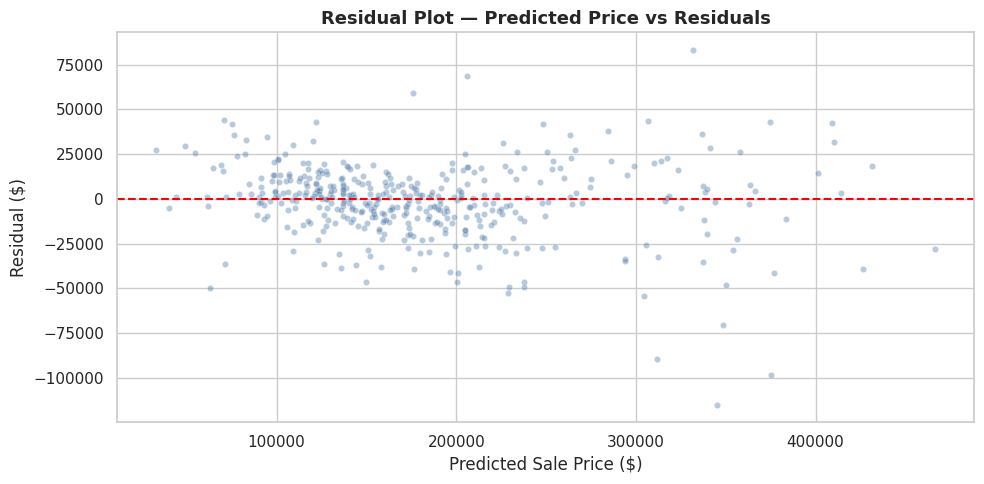

Residuals — mean  : -1,547  (should be close to 0)
Residuals — std   : 21,101
Residuals — min   : -114,996
Residuals — max   : 83,185


In [31]:
# What is a residual?
#   Residual = actual price - predicted price
#   Positive residual: the model predicted too low.
#   Negative residual: the model predicted too high.
#   A good model should have residuals that look random (no pattern).

residuals = y_test - y_pred

plt.figure(figsize=(10, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.4, s=20, color='#4C78A8')
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Predicted Sale Price ($)')
plt.ylabel('Residual ($)')
plt.title('Residual Plot — Predicted Price vs Residuals')
plt.tight_layout()
plt.savefig('../images/08_residuals.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Residuals — mean  : {residuals.mean():,.0f}  (should be close to 0)")
print(f"Residuals — std   : {residuals.std():,.0f}")
print(f"Residuals — min   : {residuals.min():,.0f}")
print(f"Residuals — max   : {residuals.max():,.0f}")

**How to read this chart:**
- Ideally, residuals should be scattered randomly around the zero line with no pattern.
- If residuals fan out (larger spread for higher predictions), this is called **heteroscedasticity** — a sign that the model struggles with expensive houses.
- This is expected with right-skewed data and linear regression.

### 4.7 Residual Distribution

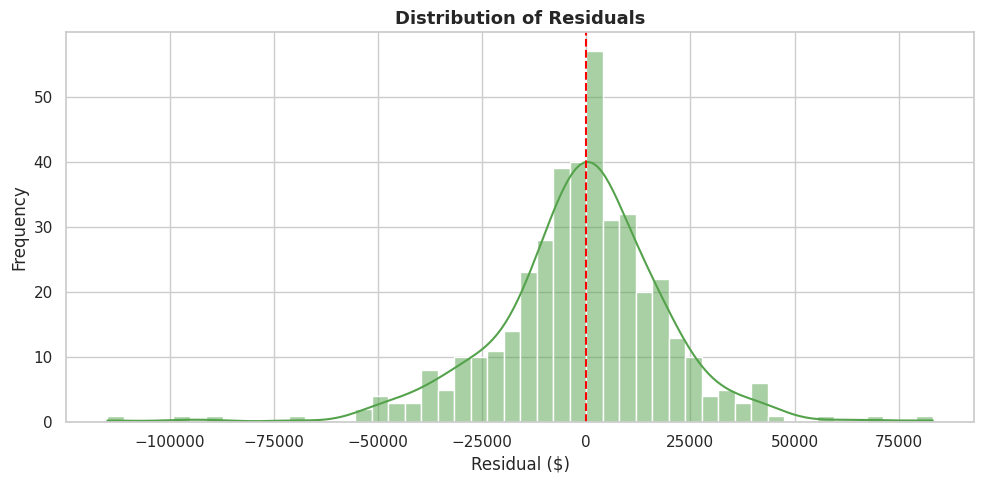

In [32]:
plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=50, kde=True, color='#54A24B')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5)
plt.title('Distribution of Residuals')
plt.xlabel('Residual ($)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('../images/09_residual_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**What we look for:**
- Ideally, residuals should be approximately normally distributed and centered at zero.
- A long right or left tail indicates the model makes large errors in one direction.

### 4.8 Feature Coefficients

In [33]:
# What are we doing?
#   Extracting the coefficient (weight) that the model assigned to each feature.
# What does a coefficient mean?
#   A positive coefficient: when this feature increases by 1 unit,
#   the predicted price increases by that amount (holding everything else constant).
#   A negative coefficient: the opposite.
# Important warnings:
#   - Coefficient size depends heavily on the unit of the feature.
#     A feature measured in square feet will have a smaller coefficient
#     than one measured in square inches — even if equally important.
#   - Coefficients of one-hot encoded categories are relative to the
#     dropped reference category.
#   - Coefficients do NOT prove causation.

feature_names  = model_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients   = model_pipeline.named_steps["model"].coef_

coef_df = pd.DataFrame({
    "Feature"    : feature_names,
    "Coefficient": coefficients
})
coef_df["AbsCoefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("AbsCoefficient", ascending=False).reset_index(drop=True)

print("Top 20 most influential features (by absolute coefficient):")
print(coef_df.head(20)[["Feature","Coefficient"]].to_string(index=False))

Top 20 most influential features (by absolute coefficient):
                  Feature    Coefficient
   cat__Roof_Matl_ClyTile -585248.933108
   cat__Misc_Feature_Elev -452988.923937
   cat__Misc_Feature_Othr  146826.340349
   cat__Roof_Matl_WdShngl  146192.696110
   cat__Roof_Matl_Membran  132739.556299
   cat__Misc_Feature_Shed  121614.411832
   cat__Misc_Feature_Gar2  121264.077649
   cat__Roof_Matl_WdShake  119670.853052
cat__Neighborhood_GrnHill  107472.284262
   cat__Roof_Matl_CompShg   99581.532223
   cat__Roof_Matl_Tar&Grv   87064.295422
      cat__Garage_Qual_Ex   85900.310164
 cat__Exterior_2nd_CBlock  -83129.512282
      cat__Garage_Cond_Ex  -81454.632800
     cat__MS_SubClass_150  -75458.863096
 cat__Exterior_1st_CBlock   71812.575560
   cat__Misc_Feature_TenC   63284.094106
   cat__MS_Zoning_A (agr)  -61566.403055
      cat__Garage_Qual_Po  -47541.356878
      cat__MS_SubClass_45   37725.144079


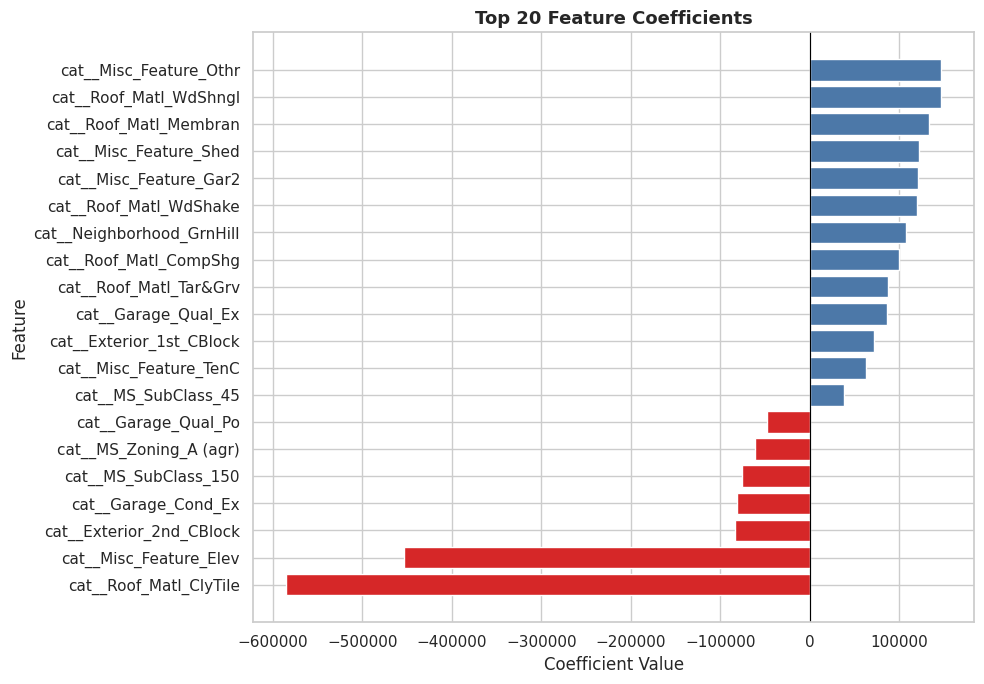

In [34]:
top20 = coef_df.head(20).sort_values("Coefficient")

plt.figure(figsize=(10, 7))
colors = ['#d62728' if c < 0 else '#4C78A8' for c in top20['Coefficient']]
plt.barh(top20['Feature'], top20['Coefficient'], color=colors)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.title('Top 20 Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('../images/10_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

**How to read this chart:**
- Blue bars (positive): increasing this feature tends to increase the predicted price.
- Red bars (negative): increasing this feature tends to decrease the predicted price.
- The length of the bar shows how strongly the model weighted that feature.

⚠️ Remember: the raw coefficient value depends on the feature's unit.
A feature measured in thousands of square feet has a naturally larger coefficient
than one measured in individual square feet, even if they are equally important to the model.

---
## Stage 5 — Model Limitations

Linear Regression is a good starting model, but it has limitations:

1. **Assumes linear relationships.** If the true relationship between a feature and price is curved (nonlinear), linear regression cannot capture it.
2. **Sensitive to outliers.** Very expensive or cheap houses can pull the regression line and hurt predictions on normal houses.
3. **Right-skewed target.** `SalePrice` is skewed — a log transformation could improve results.
4. **No feature interactions.** Linear regression treats features independently. It cannot learn that "large area + high quality = exponentially more expensive."
5. **Many one-hot encoded columns.** With 42 categorical features, one-hot encoding creates hundreds of binary columns, some very sparse.
6. **Correlation ≠ Causation.** Coefficients show associations, not causal relationships.
7. **Performance on expensive houses.** The residual plot shows larger errors for high-priced houses — common with skewed targets.

## Final Conclusion

### What was this project about?
We built a complete Machine Learning pipeline to predict house sale prices using the Ames Housing dataset (2,051 houses, 80 features).

### What did EDA reveal?
- `SalePrice` is right-skewed (skewness = 1.56). A log transform would normalize it.
- `Overall_Qual` is the strongest predictor (r = 0.80).
- `Gr_Liv_Area` and `Garage_Area` also correlate strongly with price.
- Neighborhood has a large effect — some areas have median prices 3× higher than others.
- 26 columns have missing values, most of which mean "this feature doesn't exist" (no pool, no garage).

### How was preprocessing done?
- Fixed `MS_SubClass` data type (int → string).
- Removed identifiers `Id` and `PID`.
- **Split into train/test BEFORE fitting any transformation.**
- Used `SimpleImputer` for both numerical (median) and categorical (most frequent) columns.
- Used `OneHotEncoder` with `handle_unknown="ignore"` for categories.
- Wrapped everything in a `ColumnTransformer` + `Pipeline` to prevent leakage.

### How was leakage prevented?
All preprocessing was fitted on `X_train` only, then applied to `X_test`.
The test set never influenced any imputation or encoding decision.

### Model performance?
The actual results are shown in Section 4.4. R² tells us what percentage of price variance the model explains. RMSE tells us the average prediction error in dollars.

### What could improve the model?
- Apply `log1p` transform to `SalePrice` and reverse-transform predictions.
- Try `Ridge` or `Lasso` regression to handle the large number of features.
- Engineer new features (e.g., total area = basement + floors).
- Remove or cap extreme outliers.
- Try tree-based models like Random Forest or Gradient Boosting.